# ATM-BC: topography

Corresponding Author: Feng Zhu (fengzhu@ucar.edu)

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.chdir('/glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/notebooks')
import sys
import subprocess
import numpy as np
import xarray as xr
import x4c  # optional: for better visualization
x4c.set_style('journal', font_scale=1.2)

# `utils/` sits at the repo root, four levels up from this notebook.
sys.path.append('../../../../utils/')
from Plot_2D import Plot_2D

case = 'MioMIP2_Phase2_CORE'
raw_topo_fpath = f'../data/{case}_paleogeography.nc'
scripgrid_dpath = '/glade/p/cesmdata/inputdata/share/scripgrids'

today = '260902'

## 1. Load the raw paleogeography

In [2]:
ds_raw = xr.open_dataset(raw_topo_fpath)
# Convert lon to 0-360
ds_raw = ds_raw.assign_coords(lon=(ds_raw['lon'] % 360)).sortby('lon')
ds_raw

<xarray.Dataset> Size: 12MB
Dimensions:             (lat: 721, lon: 1441)
Coordinates:
  * lat                 (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon                 (lon) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
Data variables:
    topo                (lat, lon) float32 4MB ...
    landmask            (lat, lon) float32 4MB ...
    icesheet_thickness  (lat, lon) float32 4MB ...
Attributes:
    Conventions:  CF-1.7
    title:        Paleogeography boundary condition for the MioMIP2 Phase 2 C...
    history:      
    description:  Reconstruction is at 15 Ma using the Zahirovic et al. (2022...
    GMT_version:  6.6.0 [MP]

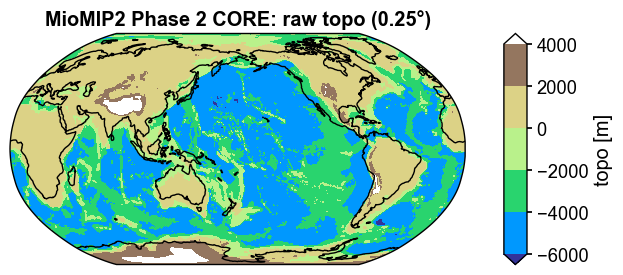

In [3]:
fig, ax = ds_raw['topo'].x.plot(title='MioMIP2 Phase 2 CORE: raw topo (0.25°)', cmap='terrain')

## 2. Per-target grid configuration

In [4]:
targets = {
    'fv19': dict(
        atm_scrip=os.path.join(scripgrid_dpath, 'fv1.9x2.5_141008.nc'),
        ref_topo='/glade/p/cesmdata/cseg/inputdata/atm/cam/topo/USGS-gtopo30_1.9x2.5_remap_c050602.nc',
    ),
    'ne30np4': dict(
        atm_scrip=os.path.join(scripgrid_dpath, 'ne30np4_091226_pentagons.nc'),
        ref_topo='/glade/p/cesmdata/cseg/inputdata/atm/cam/topo/USGS-gtopo30_ne30np4_16xdel2-PFC-consistentSGH.nc',
    ),
    'ne120np4': dict(
        atm_scrip=os.path.join(scripgrid_dpath, 'ne120np4_pentagons_100310.nc'),
        ref_topo='/glade/p/cesmdata/cseg/inputdata/atm/cam/topo/USGS-gtopo30_ne120np4_16xdel2-PFC-consistentSGH.nc',
    ),
}

output_dir = os.path.abspath('../output')
os.makedirs(output_dir, exist_ok=True)
for grid, cfg in targets.items():
    cfg['wgt'] = os.path.join(output_dir, f'map_{case}_TO_{grid}_patc.{today}.nc')
    cfg['topo_tmp'] = os.path.join(output_dir, f'topo_{case}_{grid}.{today}.nc')
    cfg['topo_out'] = os.path.join(output_dir, f'cami_bnd_topo_{grid}_{case}.{today}.nc')

## 3. Smooth the raw topo for each target grid

A grid can only carry topographic signal down to the scales it resolves; whatever
the raw 0.25° reconstruction holds below that aliases onto the coarse grid instead
of being simulated. [NCAR/Topo](https://github.com/NCAR/Topo) (Lauritzen et al.,
2015, GMD 8, 3975–3986) therefore smooths the source topography to a per-grid
scale before remapping, and its User's Guide gives the rule of thumb: *"standard
smoothing level used in CAM is 100.0 km for 1 degree applications, 50.0 km for
1/2 degree, and so on"* — i.e. a smoothing scale of ~100 km per degree of nominal
resolution.

`cube_to_target` implements this as an iterative Laplacian on a 3 km cubed-sphere
intermediate. The source here is already a smooth 0.25° reconstruction on a
regular grid, so a scale-selective Gaussian on the raw grid plays the same role.
The Gaussian's full width at half maximum is set to **2x** the NCAR/Topo scale:
that leaves ~3% amplitude at the target's 2-grid-length (Nyquist) wavelength and
~40% at 4 grid lengths, matching how CESM-standard topographies roll off --
`cube_to_target`'s own averaging window is likewise ~2x its nominal scale
(60 x scale/100 cells of the ~3.3 km cube). Taking the scale as the FWHM directly
would keep ~half the amplitude right at the Nyquist wavelength, i.e.
under-smooth:

| target | nominal resolution (Δx) | NCAR/Topo scale | Gaussian FWHM (= 2×scale) | Nyquist wavelength (2Δx) |
|---|---|---|---|---|
| `fv19` | ~2° (≈ 210 km) | 200 km | 400 km | ≈ 420 km |
| `ne30np4` | ~1° (≈ 110 km) | 100 km | 200 km | ≈ 220 km |
| `ne120np4` | ~0.25° (≈ 28 km) | 25 km | 50 km | ≈ 56 km |

For `ne120np4` the 50 km FWHM sits right at the raw source's own content limit
(the 0.25° grid holds nothing below ~56 km wavelength), so the filter only trims
the source's finest band — a small effect, but the same Nyquist rule as the
coarser grids. Since source and target spacing coincide there, the remap alone
would pass the 2Δx band straight through, which is exactly what the smoothing
exists to prevent.

In [5]:
from scipy.ndimage import gaussian_filter1d

# Smoothing scale per target, following the NCAR/Topo rule (~100 km per degree of
# nominal resolution). ne120np4's 25 km scale gives a 50 km FWHM filter -- right
# at the raw source's own content limit, but the same Nyquist rule as the rest.
for tgt, scale in {'fv19': 200.0, 'ne30np4': 100.0, 'ne120np4': 25.0}.items():
    targets[tgt]['smooth_scale_km'] = scale


def smooth_topo(topo, landmask, scale_km):
    '''Land-only Gaussian smoothing of `topo` on the raw regular grid.

    The filter's full width at half maximum is 2x `scale_km`, so the target
    grid's 2-grid-length (Nyquist) wavelength -- 2x the scale under the NCAR/Topo
    convention scale ~ grid spacing -- is essentially removed (~3% amplitude
    left) and the roll-off is gentle out to ~8 grid lengths. Separable passes: fixed sigma in latitude,
    per-row sigma/cos(lat) in longitude with mode='wrap' (the duplicated lon=180
    column of the raw grid only shifts the wrap weights by one part in 1441).
    Ocean is excluded through the smooth(topo*w)/smooth(w) normalization, so
    bathymetry never bleeds into coastal land values -- the same land-only
    principle the regrid in Section 4 uses. The landmask itself is not smoothed:
    the coastline stays exactly where the reconstruction puts it.
    '''
    lat = topo['lat'].values
    km_per_deg = 111.32
    dlat_km = km_per_deg * float(np.median(np.diff(lat)))
    dlon_km = km_per_deg * float(np.median(np.diff(topo['lon'].values)))
    sigma_km = 2 * scale_km / (2 * np.sqrt(2 * np.log(2)))  # FWHM = 2x scale -> sigma

    w = (landmask.values > 0).astype('float64')
    num = topo.values * w  # ocean contributes zero weight, not bathymetry
    num = gaussian_filter1d(num, sigma_km / dlat_km, axis=0, mode='nearest')
    den = gaussian_filter1d(w, sigma_km / dlat_km, axis=0, mode='nearest')

    nlon = topo.sizes['lon']
    for j in range(lat.size):
        # cap the per-row sigma so near-pole rows do not collapse to the mean of
        # the whole latitude circle
        coslat = max(np.cos(np.deg2rad(lat[j])), 1e-3)
        sigma_lon = min(sigma_km / (dlon_km * coslat), nlon / 6)
        num[j] = gaussian_filter1d(num[j], sigma_lon, mode='wrap')
        den[j] = gaussian_filter1d(den[j], sigma_lon, mode='wrap')

    smoothed = xr.full_like(topo.astype('float64'), np.nan)
    land = w > 0
    smoothed.values[land] = num[land] / den[land]
    return smoothed


topo_land_raw = ds_raw['topo'].where(ds_raw['landmask'] > 0)
topo_smooth = {}
for tgt, cfg in targets.items():
    scale = cfg['smooth_scale_km']
    if scale is None:
        topo_smooth[tgt] = None
        print(f'{tgt}: no smoothing (the target resolves the raw 0.25 deg topo)')
        continue
    topo_smooth[tgt] = smooth_topo(ds_raw['topo'], ds_raw['landmask'], scale)
    diff = topo_smooth[tgt] - topo_land_raw
    print(f'{tgt}: {scale:.0f} km smoothing; land-mean shift {float(diff.mean()):+.1f} m, '
          f'RMS {float((diff ** 2).mean()) ** 0.5:.0f} m, |diff| max {float(abs(diff).max()):.0f} m')

fv19: 200 km smoothing; land-mean shift +11.4 m, RMS 273 m, |diff| max 2738 m
ne30np4: 100 km smoothing; land-mean shift +5.6 m, RMS 173 m, |diff| max 2312 m
ne120np4: 25 km smoothing; land-mean shift +0.9 m, RMS 59 m, |diff| max 1493 m


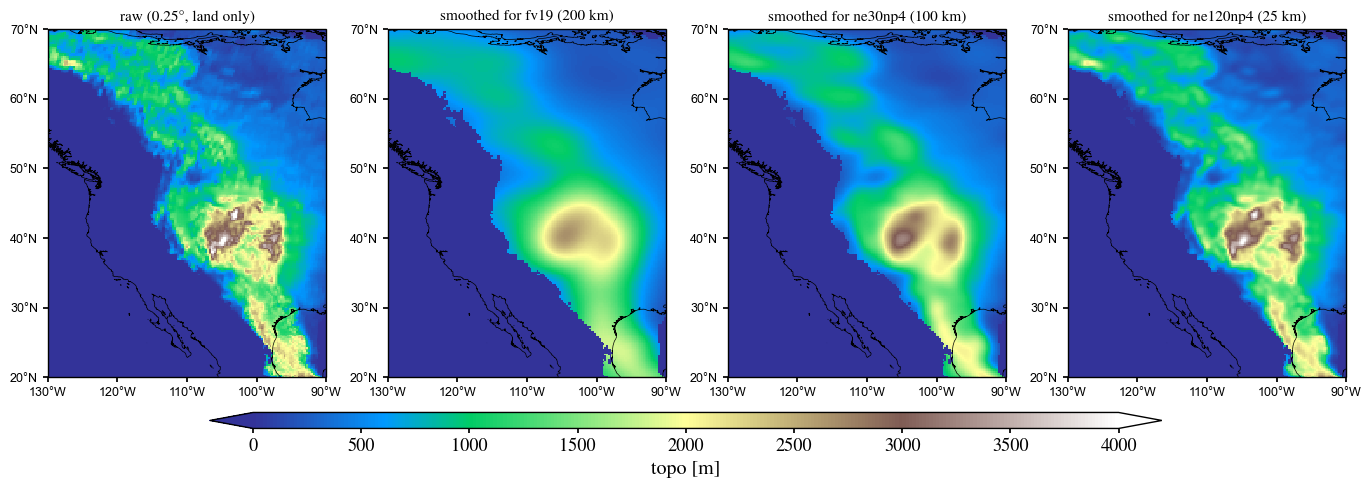

In [6]:
# Inspect what the filter removes: raw vs per-target smoothed topo over western
# North America (the same window as the PHIS panels in Section 5.1).
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

lon_range, lat_range = [-130, -90], [20, 70]
smoothed_tgts = [tgt for tgt, cfg in targets.items() if cfg['smooth_scale_km'] is not None]

kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=4000,
    lon_range=lon_range, lat_range=lat_range,
    lonlat_line=True, lon_interval=10, lat_interval=10,
    colorbar=False, nticks=9, label_size=9, title_size=11,
    coast=True, country=False, state=False,
)

fig, axes = plt.subplots(
    1, 1 + len(smoothed_tgts), figsize=(3.4 * (1 + len(smoothed_tgts)), 4),
    constrained_layout=True, subplot_kw={'projection': ccrs.PlateCarree()},
)

# Ocean -> 0 for display only, matching the later PHIS panels.
p = Plot_2D(topo_land_raw.fillna(0), ax=axes[0], title='raw (0.25°, land only)', **kws)
for ax, tgt in zip(axes[1:], smoothed_tgts):
    p = Plot_2D(
        topo_smooth[tgt].fillna(0), ax=ax,
        title=f"smoothed for {tgt} ({targets[tgt]['smooth_scale_km']:.0f} km)", **kws,
    )

cbar_ax = fig.add_axes([0.15, -0.06, 0.70, 0.04])
cb = fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='topo [m]',
)

## 4. Weight generation and regrid: raw grid -> each atm target

In [7]:
# The raw grid is *node*-centered (lat -90..90 and lon -180..180, both endpoints
# inclusive), so no CESM scripgrid matches it and it has to be read with
# --src_type GRIDSPEC. GRIDSPEC builds a mesh whose nodes are the cell centers,
# which exposes two degeneracies:
#   - Seam: the 0-360 conversion in Section 1 maps both -180 and +180 to lon=180,
#     so that column is duplicated and its elements have coincident corners at
#     every latitude. ESMF rejects this outright ("Src contains a cell that has
#     corners close enough that the cell collapses to a line or point").
#   - Poles: the explicit lat=+/-90 rows are each a single physical point repeated
#     1441 times. ESMF tolerates this (two coincident corners still leave a
#     triangle), so the pole trim is defensive rather than required -- but a pole
#     row of identical nodes interacting with the default --pole ALL is not worth
#     relying on.
# The dedup is what actually makes ESMF_RegridWeightGen succeed; the trim keeps
# the polar mesh unambiguous.
raw025_trimmed_fpath = os.path.join(output_dir, 'raw025_trimmed.nc')
ds_trim = ds_raw.isel(lat=slice(1, -1)).drop_duplicates('lon', keep='first')

# Regrid a land-only copy of topo, not the raw field. LANDFRAC here is derived by
# regridding `landmask` (there is no surfdata file for this case to take it from),
# so topo has to be regridded consistently with that mask: the remap stencil at a
# coastline otherwise mixes deep bathymetry into partially-land target cells. The
# _FillValue below, together with `ncremap --rnr_thr=0.0`, renormalizes each target
# cell by its valid (land-only) weight sum. On ne30np4 this matters for the 721
# cells with 0 < LANDFRAC < 0.99: land-only vs. raw topo differs by 156 m on
# average (max ~3300 m), and 391 of them would come out negative from the raw field
# and be flattened to 0 by the `phis < 0` clip in Section 5.
topo_land = ds_trim['topo'].where(ds_trim['landmask'] > 0)
topo_land.attrs = dict(ds_trim['topo'].attrs)
topo_land.encoding['_FillValue'] = 1.e20
ds_trim['topo_land'] = topo_land

# `raw025_trimmed.nc` keeps the unsmoothed field: it is the source *grid* for the
# weight generation (weights depend only on the grids, so one set per target
# serves every source) and the 15 Ma shoreline source for the Section 5.2 figures.
ds_trim.to_netcdf(
    raw025_trimmed_fpath,
    encoding={v: {'_FillValue': None} for v in ['topo', 'landmask', 'lat', 'lon']},
)

# Per-target source files: identical grid and landmask, but `topo_land` carries
# the Section 3 smoothed field (already land-only), subset with the same trim and
# dedup. ne120np4 keeps the raw field.
for tgt, cfg in targets.items():
    cfg['src_topo'] = os.path.join(output_dir, f'raw025_trimmed_{tgt}.nc')
    if topo_smooth[tgt] is not None:
        tl = topo_smooth[tgt].isel(lat=slice(1, -1)).drop_duplicates('lon', keep='first')
        note = f"Gaussian-smoothed at {cfg['smooth_scale_km']:.0f} km for {tgt} (Section 3, NCAR/Topo rule)"
    else:
        tl = topo_land.copy()
        note = 'unsmoothed: the raw 0.25 deg grid carries no signal this target cannot resolve'
    tl.attrs = dict(ds_trim['topo'].attrs)
    tl.attrs['smoothing'] = note
    tl.encoding['_FillValue'] = 1.e20
    ds_src = ds_trim.copy()
    ds_src['topo_land'] = tl
    ds_src.to_netcdf(
        cfg['src_topo'],
        encoding={v: {'_FillValue': None} for v in ['topo', 'landmask', 'lat', 'lon']},
    )


# Patch recovery (`-m patch`) gives a smoother, higher-order PHIS remap than
# bilinear. Its stencil can over/undershoot near sharp gradients; both clips in
# Section 5 (LANDFRAC.clip(0, 1) and `phis < 0` -> 0) tolerate that.
def build_weights(tgt, cfg):
    cmd = f'''
source $LMOD_ROOT/lmod/init/zsh
module --force purge
module load ncarenv-basic/23.10
module load gcc/13.2.0
module load mpi-serial/2.5.0
module load esmf/8.6.0
cd {output_dir}
ESMF_RegridWeightGen --ignore_unmapped -m patch -w {cfg['wgt']} \\
    -s {raw025_trimmed_fpath} -d {cfg['atm_scrip']} --src_type GRIDSPEC
'''
    subprocess.run(['bash', '-lc', cmd])


def regrid_topo(cfg):
    cmd = f'''
source $LMOD_ROOT/lmod/init/zsh
module --force purge
module load ncarenv/25.10
module load nco/5.3.4
ncremap -t 1 -m {cfg['wgt']} --rnr_thr=0.0 -v topo_land,landmask {cfg['src_topo']} {cfg['topo_tmp']}
'''
    subprocess.run(['bash', '-lc', cmd])


for tgt, cfg in targets.items():
    print(f'=== {tgt} ===')
    build_weights(tgt, cfg)
    regrid_topo(cfg)
    print(f'--> {tgt}: {cfg["topo_tmp"]}')
    print()

=== fv19 ===
 Starting weight generation with these inputs: 
   Source File: /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/raw025_trimmed.nc
   Destination File: /glade/p/cesmdata/inputdata/share/scripgrids/fv1.9x2.5_141008.nc
   Weight File: /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/map_MioMIP2_Phase2_CORE_TO_fv19_patc.260902.nc
   Source File is in CF Grid format
   Source Grid is a global grid
   Source Grid is a logically rectangular grid
   Use the center coordinates of the source grid to do the regrid
   Destination File is in SCRIP format
   Destination Grid is a global grid
   Destination Grid is a logically rectangular grid
   Use the center coordinates of the destination grid to do the regrid
   Regrid Method: patch
   Pole option: ALL
   Ignore unmapped destination points
   Line Type: cartesian
   Norm Type: dstarea
   Extrap. Method: none

 Completed weight generation successfully.

Input #00: /glade/work/fengzhu/Gi

In [8]:
# inspect the regridded topo
ds = xr.open_dataset(f'../output/topo_MioMIP2_Phase2_CORE_ne30np4.{today}.nc')
ds

<xarray.Dataset> Size: 6MB
Dimensions:       (ncol: 48602, nv: 5)
Coordinates:
    lat           (ncol) float64 389kB ...
    lon           (ncol) float64 389kB ...
Dimensions without coordinates: ncol, nv
Data variables:
    lat_vertices  (ncol, nv) float64 2MB ...
    lon_vertices  (ncol, nv) float64 2MB ...
    area          (ncol) float64 389kB ...
    landmask      (ncol) float32 194kB ...
    topo_land     (ncol) float64 389kB ...
Attributes:
    Conventions:     CF-1.7
    title:           Paleogeography boundary condition for the MioMIP2 Phase ...
    history:         Wed Sep  2 20:39:27 2026: ncks -O -t 1 --no_tmp_fl --hdr...
    description:     Reconstruction is at 15 Ma using the Zahirovic et al. (2...
    GMT_version:     6.6.0 [MP]
    remap_script:    ncremap
    remap_hostname:  crhtc124
    remap_version:   5.3.4
    NCO:             netCDF Operators version 5.3.4 (Homepage = http://nco.sf...
    map_file:        /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocen...
    input_file:      /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocen...

## 5.1 Derive `PHIS`, `LANDFRAC`, `LANDM_COSLAT`, `SGH`, `SGH30` (baseline)

The is our baseline: SGH / SGH30 are directly derived from present day at the same target grid.
A 1.5x inflation is applied to compensate for the source topo already being smoother than the GTOP030 data the reference SGH was built from.
The Section 3 smoothing makes the source smoother still, which that inflation now also has to cover.

In [9]:
grav = 9.80616

for tgt, cfg in targets.items():
    with xr.open_dataset(cfg['topo_tmp']) as ds:
        ds = ds.reset_coords()

        # Get LANDFRAC from the regridded landmask
        landfrac = ds['landmask'].astype('float64').clip(0, 1)
        landfrac.attrs = {'long_name': 'gridbox land fraction'}
        ds['LANDFRAC'] = landfrac

        # Compute LANDM_COSLAT without smoothing (not used by CAM5/6)
        landm_coslat = landfrac * np.cos(np.deg2rad(ds['lat']))
        landm_coslat.attrs = {
            'long_name': 'land ocean transition mask: ocean (0), continent (1), transition (0-1)',
            'NOTE1': 'This field has not been smoothed',
            'NOTE2': 'This field is not used by CAM5/6',
        }
        ds['LANDM_COSLAT'] = landm_coslat

        # Compute PHIS
        phis = ds['topo_land'].astype('float64') * grav
        phis.attrs = {
            'long_name': 'surface geopotential',
            'units': 'm2/s2',
            'from_hires': 'false',
        }
        phis = xr.where(landfrac > 0, phis, 0)
        phis = xr.where(phis < 0, 0, phis)
        ds['PHIS'] = phis

        # Fit PHIS -> SGH / SGH30 from this target's resolution-matched reference file.
        # Select land columns through a flat numpy mask so both layouts work:
        # the SE references are 1-D on `ncol`, the FV reference is 2-D on (lat, lon).
        ds_ref = xr.open_dataset(cfg['ref_topo'])
        ref_land = ds_ref['LANDFRAC'].values > 0
        phis_ref = ds_ref['PHIS'].values[ref_land]
        sgh_ref = ds_ref['SGH'].values[ref_land]
        sgh30_ref = ds_ref['SGH30'].values[ref_land]

        phis_to_sgh = np.polyfit(phis_ref, sgh_ref, 1)
        phis_to_sgh30 = np.polyfit(phis_ref, sgh30_ref, 1)

        # Compute SGH
        # Artificially increase slope by 50% to account for the coarse/smooth source topo.
        sgh = phis * phis_to_sgh[0] * 1.5 + phis_to_sgh[1]
        sgh.attrs = {
            'long_name': 'standard deviation of 10-min elevations',
            'units': 'm',
            'creation': f"linear regression against {os.path.basename(cfg['ref_topo'])}, 50% larger slope",
        }
        ds['SGH'] = sgh.astype('float64')

        # Compute SGH30
        # Artificially increase slope by 50% to account for the coarse/smooth source topo.
        sgh30 = phis * phis_to_sgh30[0] * 1.5 + phis_to_sgh30[1]
        sgh30.attrs = {
            'long_name': 'standard deviation of elevation from 30s to 10m',
            'units': 'm',
            'creation': f"linear regression against {os.path.basename(cfg['ref_topo'])}, 50% larger slope",
        }
        ds['SGH30'] = sgh30

        # Drop variables that are not needed. A keep-list, so the FV extras
        # (gw, lat_bnds, lon_bnds, area) go the same way as the SE vertices.
        keep = ['lat', 'lon', 'LANDFRAC', 'LANDM_COSLAT', 'PHIS', 'SGH', 'SGH30']
        ds = ds.drop_vars([v for v in ds.data_vars if v not in keep])

        # Set missing value
        for da in ds.data_vars.values():
            da.attrs['missing_value'] = 1.e+36
            da.attrs['_FillValue'] = 1.e+36

        ds.attrs['author'] = 'Feng Zhu (fengzhu@ucar.edu)'

        if os.path.exists(cfg['topo_out']):
            os.remove(cfg['topo_out'])
        ds.to_netcdf(cfg['topo_out'], format='NETCDF3_64BIT')

    print(f'--> {tgt}: {cfg["topo_out"]}')

--> fv19: /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_fv19_MioMIP2_Phase2_CORE.260902.nc
--> ne30np4: /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_ne30np4_MioMIP2_Phase2_CORE.260902.nc
--> ne120np4: /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_ne120np4_MioMIP2_Phase2_CORE.260902.nc


In [10]:
# inspect the output
ds_out = {tgt: xr.open_dataset(cfg['topo_out']) for tgt, cfg in targets.items()}
ds_out['ne30np4']

<xarray.Dataset> Size: 3MB
Dimensions:       (ncol: 48602)
Dimensions without coordinates: ncol
Data variables:
    lat           (ncol) float64 389kB ...
    lon           (ncol) float64 389kB ...
    LANDFRAC      (ncol) float64 389kB ...
    LANDM_COSLAT  (ncol) float64 389kB ...
    PHIS          (ncol) float64 389kB ...
    SGH           (ncol) float64 389kB ...
    SGH30         (ncol) float64 389kB ...
Attributes:
    Conventions:     CF-1.7
    title:           Paleogeography boundary condition for the MioMIP2 Phase ...
    history:         Wed Sep  2 20:39:27 2026: ncks -O -t 1 --no_tmp_fl --hdr...
    description:     Reconstruction is at 15 Ma using the Zahirovic et al. (2...
    GMT_version:     6.6.0 [MP]
    remap_script:    ncremap
    remap_hostname:  crhtc124
    remap_version:   5.3.4
    NCO:             netCDF Operators version 5.3.4 (Homepage = http://nco.sf...
    map_file:        /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocen...
    input_file:      /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocen...
    author:          Feng Zhu (fengzhu@ucar.edu)

CPU times: user 7.23 s, sys: 223 ms, total: 7.45 s
Wall time: 7.45 s


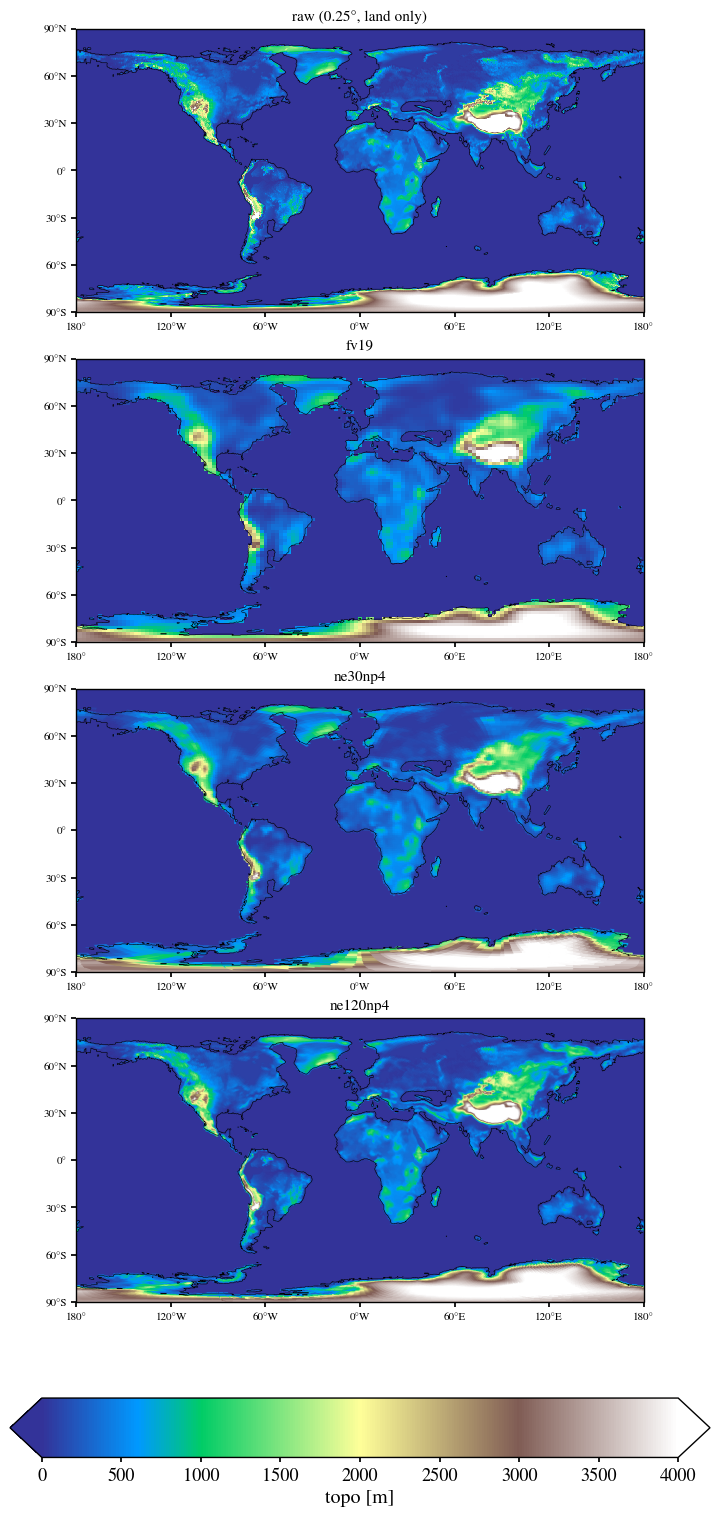

In [11]:
%%time

# Same panels (raw + one per target), global. `dict(kws, ...)` reuses the settings above and only
# overrides the window and the gridline spacing.
#
# `coast=False` here: at global scale the modern coastline is visibly offset from
# the reconstruction -- the plates have moved 15 Myr -- so the 15 Ma shoreline is
# overlaid from the landmask instead.
glon_range, glat_range = [-180, 180], [-90, 90]

# `coast=False`: this is a 15 Ma reconstruction, so modern coastlines would be
# misleading -- the land/ocean boundary is already in the field itself.
kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=4000,
    lon_range=lon_range, lat_range=lat_range,
    lonlat_line=True, lon_interval=10, lat_interval=10,
    colorbar=False, nticks=9, label_size=9, title_size=11,
    coast=True, country=False, state=False,
)


topo_kws_global = dict(
    kws,
    lon_range=glon_range, lat_range=glat_range,
    lon_interval=60, lat_interval=30,
    coast=False, label_size=8,
)

fig, axes = plt.subplots(
    1 + len(ds_out), 1, figsize=(10, 3.3 * (1 + len(ds_out))), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

p = Plot_2D(
    ds_raw['topo'].where(ds_raw['landmask'] > 0, 0), ax=axes[0],
    title='raw (0.25°, land only)', **topo_kws_global,
)

# ne120np4 is ~777k polygons, so this panel takes ~30 s.
for ax, (tgt, ds) in zip(axes[1:], ds_out.items()):
    p = Plot_2D(
        ds['PHIS'] / grav, ax=ax,
        scrip_file=targets[tgt]['atm_scrip'], title=tgt, **topo_kws_global,
    )

# 15 Ma shoreline from the raw landmask, on the -180..180 axis Plot_2D shifted to.
_lon_g = ((ds_raw['lon'].values + 180) % 360) - 180
_o_g = np.argsort(_lon_g)
for ax in axes:
    ax.contour(_lon_g[_o_g], ds_raw['lat'].values, ds_raw['landmask'].values[:, _o_g],
               levels=[0.5], colors='k', linewidths=0.4, transform=ccrs.PlateCarree())

cbar_ax = fig.add_axes([0.15, -0.10, 0.70, 0.045])
cb = fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='topo [m]',
)

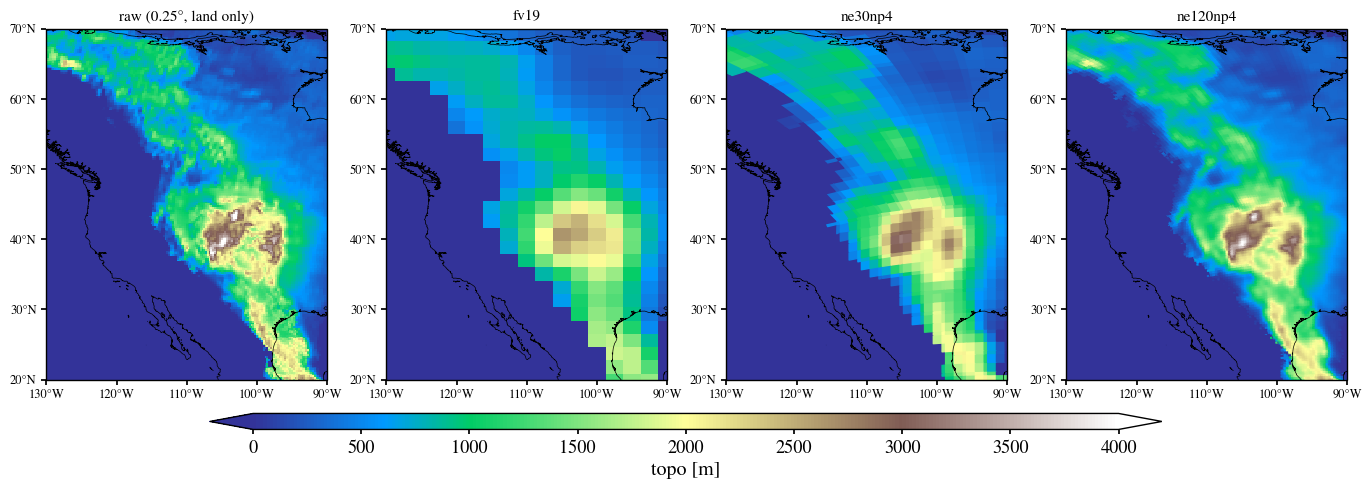

In [12]:
# Visualize the raw topo and the regridded PHIS fields.
# The raw topo is 2-D on lat/lon, so Plot_2D takes the FV path (no scripgrid needed). The regridded fields are 1-D on `ncol`, so Plot_2D takes the SE path and needs the matching scripgrid for the element corners.
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
lon_range, lat_range = [-130, -90], [20, 70]

fig, axes = plt.subplots(
    1, 1 + len(ds_out), figsize=(3.4 * (1 + len(ds_out)), 4), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# Raw 0.25 deg source is 2-D lat/lon, so Plot_2D takes the FV path (no scripgrid
# needed). Ocean -> 0 to match the regridded PHIS panels, which are 0 over ocean
# by construction (Section 5) rather than showing bathymetry.
p = Plot_2D(
    ds_raw['topo'].where(ds_raw['landmask'] > 0, 0), ax=axes[0],
    title='raw (0.25°, land only)', **kws,
)

# The regridded fields are 1-D on `ncol`, so Plot_2D takes the SE path and needs
# the matching scripgrid for the element corners. ne120np4 is ~777k polygons and
# takes ~30 s to draw.
for ax, (tgt, ds) in zip(axes[1:], ds_out.items()):
    p = Plot_2D(
        ds['PHIS'] / grav, ax=ax,
        scrip_file=targets[tgt]['atm_scrip'], title=tgt, **kws,
    )

# Shared colorbar keyed off the last mappable -- all three panels use the same
# cmap and cmin/cmax, so any of them would do.
cbar_ax = fig.add_axes([0.15, -0.06, 0.70, 0.04])
cb = fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='topo [m]',
)

## 5.2 Rotation-Interpolation based SGH / SGH30

In [13]:
ds_tmp = xr.open_dataset('/glade/p/cesmdata/cseg/inputdata/atm/cam/topo/USGS-gtopo30_ne30np4_16xdel2-PFC-consistentSGH.nc')
ds_tmp

<xarray.Dataset> Size: 3MB
Dimensions:       (ncol: 48602)
Dimensions without coordinates: ncol
Data variables:
    PHIS          (ncol) float64 389kB ...
    LANDFRAC      (ncol) float64 389kB ...
    SGH           (ncol) float64 389kB ...
    SGH30         (ncol) float64 389kB ...
    LANDM_COSLAT  (ncol) float64 389kB ...
    lat           (ncol) float64 389kB ...
    lon           (ncol) float64 389kB ...
Attributes:
    source:   USGS 30-sec dataset binned to ncube3000 (cube-sphe
    title:    30-second USGS topo data
    history:  Written on date: 20120803

Section 5.1 derives `SGH` / `SGH30` as a linear function of `PHIS`, so the subgrid
roughness is smooth by construction and carries no information about *where* the
terrain actually was. Here we take the alternative route used in
[rpacosta07/MioMIP2_Reconstruction_Spatial_Interpolation](https://github.com/rpacosta07/MioMIP2_Reconstruction_Spatial_Interpolation/blob/main/Z22_Reconstruction-Interpolation-Example.ipynb):
carry a present-day field to its palaeo position with the plate model, then fill
whatever gaps the rotation leaves.

Applied to roughness, per target grid:

1. take present-day `SGH` / `SGH30` from that target's **own** reference topo,
   masked to present-day land;
2. rotate those columns to 15 Ma with the Zahirovic et al. (2022) model via
   `gplately.Points` (anchor plate 701701, the palaeomagnetic frame);
3. give each Miocene column the nearest rotated column within one grid spacing —
   the ~5–7% with nothing that close are gaps, filled three ways: left blank,
   nearest neighbour (`sit.fast_interpolate`), and universal kriging with a
   spherical variogram (`sit.slow_interpolate`).

The kriging variant is written to `cami_bnd_topo_*_rotsgh.*.nc`; the other two
exist for the comparison figure at the end of this section.

**No regular grid is involved.** The reference notebook rotates a raster because
`gplately.Raster` requires one, and an earlier version of this section followed
it — upsampling the SE mesh to the 0.25° grid, rotating, then regridding back
with the Section 4 weights. `gplately.Points` accepts the column lon/lat from the
topo file directly, and the SE grids never move (only the terrain does), so the
rotation goes straight from `ncol` to `ncol`. That removes two interpolations,
the 0.25° intermediates and the `ncremap` calls.

Going column-to-column also makes per-target sourcing cheap, which is what keeps
`SGH` resolution-matched the way 5.1 is: roughness grows with cell size (the
present-day ne30np4 reference has 1.85× the land-mean `SGH` of ne120np4), so
ne30np4 must inherit ne30np4 roughness.

Unlike 5.1 there is no 1.5x inflation: the rotated field already carries real
present-day roughness rather than a regression against a smoothed topography.

Two caveats worth keeping in view:

- **Roughness is assumed time-invariant per land parcel over 15 Myr** — the same
  assumption the reference notebook makes for climate fields. Where 15 Ma relief
  genuinely differs from today (uplift, erosion), this is wrong in a way the
  regression approach is not.
- **Coastal columns are sampled, not area-averaged.** The old raster route ran
  `ncremap --rnr_thr=0.0`, which averaged land-only source cells into
  partially-land target cells. Column-to-column nearest-neighbour gives each
  target one rotated value instead — natural now that source and target column
  densities match, but a real difference at coastlines.

In [14]:
import time
from concurrent.futures import ProcessPoolExecutor
from scipy.spatial import cKDTree
from pykrige.uk import UniversalKriging
import gplately
import plate_model_manager

recon_time = 15  # Ma -- matches the MioMIP2 Phase 2 CORE reconstruction

# ~85 MB of rotations / static polygons / topologies, so keep it out of the repo.
# The first run downloads it from the Plate Model Manager servers; after that the
# readonly branch picks up the local copy.
plate_model_dir = '../../../../utils/platemodels'
os.makedirs(plate_model_dir, exist_ok=True)
try:
    Z22_pmm = plate_model_manager.PlateModel(
        'Zahirovic2022', data_dir=plate_model_dir, readonly=True)
except Exception:
    Z22_pmm = plate_model_manager.PlateModelManager().get_model(
        'Zahirovic2022', data_dir=plate_model_dir)

Z22_static_polygons = Z22_pmm.get_static_polygons()
# anchor_plate_id=701701 is the palaeomagnetic reference frame
Z22_model = gplately.PlateReconstruction(
    Z22_pmm.get_rotation_model(),
    Z22_pmm.get_topologies(),
    Z22_static_polygons,
    anchor_plate_id=701701,
)

# Only needed for the 15 Ma shoreline overlay in the comparison figure -- the
# rotation below never touches a regular grid.
ds_raw025 = xr.open_dataset(raw025_trimmed_fpath)

# A target column counts as covered if a rotated present-day column lands within
# this many grid spacings of it. 1.0 is the natural reading ("within one cell").
# Sensitivity at ne120np4: 0.75 -> 21.6% gaps, 1.0 -> 7.3%, 1.5 -> 5.3%, 2.0 ->
# 4.5%. The steep drop below 1.0 is sampling noise; the flat tail above 1.5 is
# genuine new Miocene land that no present-day parcel maps onto.
gap_radius_factor = 1.0

# Neighbours per kriging solve. The solve is O(k^3), and once the variogram is
# fixed (see `fit_variogram`) accuracy is flat in k: on held-out columns, k=100 /
# 50 / 25 gave MAE 50.7 / 50.6 / 50.5 m at ne30np4 and 23.8 / 23.6 / 23.2 m at
# ne120np4. 50 keeps comfortable margin over the 3 drift coefficients.
krig_spacing = 50


def _xyz(lon, lat):
    '''Unit-sphere Cartesian coords, so nearest-neighbour searches don't care
    about the lon seam or converging meridians.'''
    lo, la = np.deg2rad(lon), np.deg2rad(lat)
    return np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], axis=-1)


def grid_spacing_deg(lon, lat):
    '''Median nearest-neighbour separation of an unstructured grid, in degrees.'''
    d, _ = cKDTree(_xyz(lon, lat)).query(_xyz(lon, lat), k=2, workers=-1)
    return np.rad2deg(2 * np.arcsin(np.median(d[:, 1]) / 2))


def column_lonlat(ds):
    '''Per-column lon/lat as flat 1-D arrays, for either layout: SE files carry
    one value per column already; FV files carry 1-D axes that mesh out.'''
    if 'ncol' in ds['lon'].dims:  # SE
        return ds['lon'].values, ds['lat'].values
    lon2, lat2 = np.meshgrid(ds['lon'].values, ds['lat'].values)
    return lon2.ravel(), lat2.ravel()


def rotate_columns(ds_src, names, src_land, dst_lon, dst_lat, radius_deg):
    '''Rotate present-day source columns to `recon_time`, sample onto dst columns.

    The SE grids do not move -- only the terrain does -- so this goes straight
    from one set of `ncol` coordinates to another. No regular grid is involved:
    the reference notebook needs one because `gplately.Raster` demands it, but
    `gplately.Points` takes the column lon/lat from the topo file as they are.

    Rotating moves *coordinates*, so one call serves every field in `names`.
    Returns the sampled fields plus the coverage mask (False = gap to fill).
    '''
    src_lon, src_lat = column_lonlat(ds_src)     # FV refs arrive 2-D; work on flat columns
    src_land = np.asarray(src_land).ravel()
    lon_pd = ((src_lon[src_land] + 180) % 360) - 180  # gplately wants -180..180
    lat_pd = src_lat[src_land]

    # `remove_unreconstructable_points=False` is required, not cosmetic: with True
    # the indices returned below refer to gplately's trimmed internal array rather
    # than to `lon_pd`/`lat_pd`, so `values[keep]` would be silently misaligned.
    pts = gplately.Points(Z22_model, lon_pd, lat_pd,
                          remove_unreconstructable_points=False)
    rlon, rlat, keep = pts.reconstruct(
        recon_time, return_array=True, return_point_indices=True)
    assert np.allclose(pts.lons[keep], lon_pd[keep]), 'point indices are misaligned'

    cutoff = 2 * np.sin(np.deg2rad(radius_deg) / 2)  # degrees -> chord length
    dist, j = cKDTree(_xyz(rlon, rlat)).query(_xyz(dst_lon, dst_lat), workers=-1)
    covered = dist <= cutoff

    out = {n: np.where(covered, ds_src[n].values.ravel()[src_land][keep][j], np.nan)
           for n in names}
    return out, covered


def fill_nearest(vals, lon, lat, fill_mask):
    '''Fill from the nearest valid column -- `sit.fast_interpolate`, method='nearest'.'''
    need = fill_mask & ~np.isfinite(vals)
    if not need.any():
        return vals
    good = np.isfinite(vals)
    _, j = cKDTree(_xyz(lon[good], lat[good])).query(
        _xyz(lon[need], lat[need]), workers=-1)
    out = vals.copy()
    out[need] = vals[good][j]
    return out


# --- kriging gap-fill: `sit.slow_interpolate`, made tractable ------------------

def fit_variogram(vals, lon, lat, n_patches=40, spacing=100,
                  variogram_model='spherical', seed=0):
    '''Fit the variogram ONCE, at the lag scale the kriging actually uses.

    `sit.slow_interpolate` -- and the first version of this notebook -- refits a
    variogram inside every solve, i.e. tens of thousands of independent fits from
    100 points each. That is ~95% of the runtime and it is *worse*: a 100-point
    fit is badly under-determined, and on held-out columns the per-point scheme
    scored MAE 56.2 m at ne30np4 against 50.6 m for the pooled fit below, barely
    beating plain nearest-neighbour (59.0 m).

    Fitting on a *global* sample does not work either -- those lags all sit far
    beyond the correlation length, the fit collapses to pure nugget (range -> 0)
    and MAE roughly doubles. Pooling real neighbourhood patches is what keeps the
    lag range honest.

    Returns a dict keyed `'psill'`, deliberately: pykrige treats a bare list and
    the `'sill'` key as a *total* sill and subtracts the nugget, so feeding back
    `variogram_model_parameters` (which is [psill, range, nugget]) through either
    of those silently shrinks the partial sill.
    '''
    valid = np.flatnonzero(np.isfinite(vals))
    tree = cKDTree(_xyz(lon[valid], lat[valid]))
    rng = np.random.default_rng(seed)
    params = []
    for i in rng.choice(valid, min(n_patches, valid.size), replace=False):
        _, nb = tree.query(_xyz(lon[i], lat[i]), k=spacing)
        dlon = ((lon[valid][nb] - lon[i] + 180.0) % 360.0) - 180.0
        dlat = lat[valid][nb] - lat[i]
        try:
            uk = UniversalKriging(dlon, dlat, vals[valid][nb],
                                  variogram_model=variogram_model,
                                  drift_terms=['linear'], verbose=False,
                                  enable_plotting=False)
            params.append(uk.variogram_model_parameters)
        except Exception:
            pass
    psill, range_, nugget = np.median(np.array(params), axis=0)
    return {'psill': psill, 'range': range_, 'nugget': nugget}


# Workers share the KD-tree and every field's values through this module-level
# dict, populated once per worker by `_krig_init`.
_KRIG = {}


def _krig_init(vxyz, vlon, vlat, vvals, vparams, variogram_model, spacing):
    _KRIG.update(tree=cKDTree(vxyz), vlon=vlon, vlat=vlat, vvals=vvals,
                 vparams=vparams, vgm=variogram_model, k=spacing)


def _krig_solve(args):
    '''Solve every field at one gap column, sharing the neighbour lookup.'''
    tlon_i, tlat_i, txyz = args
    g = _KRIG
    # One query serves all fields: they come from the same rotation, so their
    # valid masks -- and therefore their neighbour sets -- are identical.
    _, nb = g['tree'].query(txyz, k=g['k'], workers=1)
    # Krige in a frame centred on the target column: this unwraps the longitude
    # seam and keeps the linear drift term well conditioned at high latitude.
    dlon = ((g['vlon'][nb] - tlon_i + 180.0) % 360.0) - 180.0
    dlat = g['vlat'][nb] - tlat_i
    out = []
    for name, vals in g['vvals'].items():
        val = vals[nb]
        try:
            kr = UniversalKriging(dlon, dlat, val, variogram_model=g['vgm'],
                                  drift_terms=['linear'],
                                  variogram_parameters=g['vparams'][name],
                                  verbose=False, enable_plotting=False)
            out.append(float(kr.execute('points', np.array([0.0]), np.array([0.0]))[0][0]))
        except Exception:
            out.append(float(val[0]))  # degenerate neighbourhood -> nearest valid
    return out


def fill_kriging(fields, lon, lat, fill_mask, variogram_model='spherical',
                 spacing=None, workers=16, chunk=64, verbose=True):
    '''Kriging gap-fill for several fields at once.

    `fields` is {name: 1-D array}. All of them must share the same valid mask --
    true here because they come from one rotation -- which is what lets a single
    KD-tree and a single neighbour lookup serve every field.

    Deviations from `sit.slow_interpolate`, both measured:
      * the variogram is fitted once per field (see `fit_variogram`) instead of
        once per gap column: ~2x faster and ~10% lower MAE;
      * `spacing` neighbours come from a KD-tree rather than an O(N) argsort per
        point, and `spacing=50` rather than 100 is ~2.5x faster at equal accuracy.
    Together ~5x against the per-point scheme, and more accurate.

    The kriging itself is untouched: universal kriging, spherical variogram,
    linear drift, in the target-centred frame.
    '''
    spacing = krig_spacing if spacing is None else spacing
    names = list(fields)
    valid = np.isfinite(fields[names[0]])
    for n in names[1:]:
        assert np.array_equal(np.isfinite(fields[n]), valid), \
            f'{n} has a different valid mask; the shared neighbour lookup assumes one mask'
    need = fill_mask & ~valid
    if not need.any():
        return dict(fields)

    t0 = time.time()
    params = {n: fit_variogram(fields[n], lon, lat) for n in names}
    if verbose:
        for n in names:
            p = params[n]
            print(f'    {n} variogram: psill={p["psill"]:.0f} '
                  f'range={p["range"]:.3f} deg nugget={p["nugget"]:.0f}')
        print(f'    fitted {len(names)} variograms in {time.time() - t0:.0f} s; '
              f'{int(need.sum())} gap columns x {len(names)} fields')

    args = list(zip(lon[need], lat[need], _xyz(lon[need], lat[need])))
    with ProcessPoolExecutor(
        workers, initializer=_krig_init,
        initargs=(_xyz(lon[valid], lat[valid]), lon[valid], lat[valid],
                  {n: fields[n][valid] for n in names}, params,
                  variogram_model, spacing),
    ) as ex:
        rows = list(ex.map(_krig_solve, args, chunksize=chunk))

    rows = np.asarray(rows)
    out = {}
    for c, n in enumerate(names):
        a = fields[n].copy()
        a[need] = rows[:, c]
        out[n] = a
    return out

In [15]:
%%time

# Each target rotates its *own* reference topo, straight from ncol to ncol. That
# restores the resolution matching 5.1 has -- SGH grows with cell size, so
# ne30np4 needs ne30np4 roughness, not ne120np4's.
FILLS = ['raw', 'nn', 'krig']  # unfilled / nearest / kriging
ROT_VARS = ['SGH', 'SGH30']

for tgt, cfg in targets.items():
    for f in FILLS:
        cfg[f'sgh_rot_se_{f}'] = os.path.join(
            output_dir, f'sgh_rot_{f}_{case}_{tgt}.{today}.nc')
    cfg['topo_out_rot'] = os.path.join(
        output_dir, f'cami_bnd_topo_{tgt}_{case}_rotsgh.{today}.nc')

for tgt, cfg in targets.items():
    t0 = time.time()
    print(f'=== {tgt} ===')
    ds_src = xr.open_dataset(cfg['ref_topo'])
    ds_dst = xr.open_dataset(cfg['topo_out'])          # 5.1 output: the Miocene grid
    dlon, dlat = column_lonlat(ds_dst)                 # flat columns for SE and FV alike
    mio_land = ds_dst['LANDFRAC'].values.ravel() > 0

    radius = gap_radius_factor * grid_spacing_deg(dlon, dlat)
    # Mask to present-day land before rotating: ocean columns carry no meaningful
    # roughness and would smear onto Miocene continents. One rotation call covers
    # both fields, since what moves is the column coordinates.
    rot, covered = rotate_columns(
        ds_src, ROT_VARS, ds_src['LANDFRAC'].values > 0, dlon, dlat, radius)

    n_gap = int((mio_land & ~covered).sum())
    print(f'  rotated in {time.time() - t0:.0f} s; gap radius {radius:.2f} deg; '
          f'{n_gap} / {int(mio_land.sum())} Miocene-land columns '
          f'({100 * n_gap / mio_land.sum():.1f}%) had no present-day parcel land on them')

    variants = {'raw': rot,
                'nn': {n: fill_nearest(rot[n], dlon, dlat, mio_land) for n in ROT_VARS}}
    # Both fields in one pass: same gap columns, same neighbour sets, so the
    # KD-tree and the per-column lookup are built once and reused.
    t1 = time.time()
    variants['krig'] = fill_kriging(rot, dlon, dlat, mio_land)
    print(f'  kriging {ROT_VARS} together: {time.time() - t1:.0f} s')

    # Keep Miocene land only; ocean is set in the assembly cell below.
    # Written in the target's native layout -- flat ncol for SE, (lat, lon) for
    # FV -- so the assembly and comparison cells treat the rotated files exactly
    # like the 5.1 outputs.
    tmpl = ds_dst['LANDFRAC']
    for f in FILLS:
        ds_rot = xr.Dataset(
            {f'{n}_rot': (tmpl.dims,
                          np.where(mio_land, variants[f][n], np.nan).reshape(tmpl.shape))
             for n in ROT_VARS})
        if tmpl.ndim == 1:  # SE: per-column coords
            ds_rot = ds_rot.assign_coords(lat=('ncol', dlat), lon=('ncol', dlon))
        else:               # FV: 1-D axis coords
            ds_rot = ds_rot.assign_coords(lat=ds_dst['lat'], lon=ds_dst['lon'])
        for v in ds_rot.data_vars.values():
            v.encoding['_FillValue'] = 1.e20
        ds_rot.to_netcdf(cfg[f'sgh_rot_se_{f}'],
                         encoding={c: {'_FillValue': None} for c in ['lat', 'lon']})
    print(f'  --> {cfg["sgh_rot_se_krig"]}  ({time.time() - t0:.0f} s total)')

=== fv19 ===
  rotated in 0 s; gap radius 1.75 deg; 60 / 5010 Miocene-land columns (1.2%) had no present-day parcel land on them
    SGH variogram: psill=12281 range=23.386 deg nugget=292
    SGH30 variogram: psill=2054 range=22.135 deg nugget=45
    fitted 2 variograms in 2 s; 60 gap columns x 2 fields
  kriging ['SGH', 'SGH30'] together: 3 s
  --> /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/sgh_rot_krig_MioMIP2_Phase2_CORE_fv19.260902.nc  (4 s total)
=== ne30np4 ===
  rotated in 1 s; gap radius 0.74 deg; 729 / 15049 Miocene-land columns (4.8%) had no present-day parcel land on them
    SGH variogram: psill=9565 range=9.602 deg nugget=1128
    SGH30 variogram: psill=524 range=9.610 deg nugget=37
    fitted 2 variograms in 2 s; 729 gap columns x 2 fields
  kriging ['SGH', 'SGH30'] together: 4 s
  --> /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/sgh_rot_krig_MioMIP2_Phase2_CORE_ne30np4.260902.nc  (5 s total)
=== ne120np4 ===
  rot

### Inspect the results

In [16]:
%%time

# Start from the 5.1 baseline and swap in the rotated roughness -- everything else
# (PHIS, LANDFRAC, LANDM_COSLAT) is identical between the two files.
# The kriging variant is the deliverable: the reference notebook treats it as the
# better of the two fills, and it is smooth across the gap boundaries where the
# nearest fill leaves visible steps. Set `deliverable_fill = 'nn'` to ship the
# nearest-filled version instead.
deliverable_fill = 'krig'

for tgt, cfg in targets.items():
    ds = xr.open_dataset(cfg['topo_out']).load()
    ds_rot = xr.open_dataset(cfg[f'sgh_rot_se_{deliverable_fill}'])[['SGH_rot', 'SGH30_rot']]
    # Drop lat/lon: they are coords in the rotated file but plain data variables
    # in the 5.1 output, and xarray refuses to merge the two.
    ds_rot = ds_rot.reset_coords(drop=True).load()

    land = ds['LANDFRAC'] > 0
    for name in ['SGH', 'SGH30']:
        rot_se = ds_rot[f'{name}_rot'].astype('float64')
        # NOTE: this zeroes SGH over ocean, which the 5.1 baseline does *not* do --
        # there SGH = intercept (116.8 m at ne30np4, 58.2 m at ne120np4) wherever
        # PHIS == 0, since the regression is never masked to land. Zero is the
        # defensible value for a roughness field, but it does mean the two files
        # differ over ocean as well as over land.
        rot_se = xr.where(land, rot_se, 0)
        rot_se = xr.where(rot_se < 0, 0, rot_se)
        rot_se = rot_se.fillna(0)
        rot_se.attrs = dict(ds[name].attrs)
        rot_se.attrs['creation'] = (
            f"present-day {name} from {os.path.basename(cfg['ref_topo'])} rotated to "
            f'{recon_time} Ma with the Zahirovic et al. (2022) model via gplately '
            f'(anchor plate 701701), sampled column-to-column; gaps filled by '
            f'{deliverable_fill}'
        )
        ds[name] = rot_se

    for da in ds.data_vars.values():
        # The 5.1 output already carries these in `encoding`; setting them as attrs
        # too makes xarray refuse to write.
        da.encoding.pop('_FillValue', None)
        da.encoding.pop('missing_value', None)
        da.attrs['missing_value'] = 1.e+36
        da.attrs['_FillValue'] = 1.e+36

    ds.attrs['author'] = 'Feng Zhu (fengzhu@ucar.edu)'

    if os.path.exists(cfg['topo_out_rot']):
        os.remove(cfg['topo_out_rot'])
    ds.to_netcdf(cfg['topo_out_rot'], format='NETCDF3_64BIT')

    ds_base = xr.open_dataset(cfg['topo_out'])
    m = ds_base['LANDFRAC'] > 0
    print(f'{tgt}: land-mean SGH  regression {float(ds_base["SGH"].where(m).mean()):.1f} m'
          f'  vs rotation {float(ds["SGH"].where(m).mean()):.1f} m'
          f'  (corr {float(xr.corr(ds_base["SGH"].where(m), ds["SGH"].where(m))):.3f})')
    print(f'  --> {cfg["topo_out_rot"]}')

fv19: land-mean SGH  regression 207.4 m  vs rotation 200.0 m  (corr 0.035)
  --> /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_fv19_MioMIP2_Phase2_CORE_rotsgh.260902.nc
ne30np4: land-mean SGH  regression 231.9 m  vs rotation 204.0 m  (corr 0.341)
  --> /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_ne30np4_MioMIP2_Phase2_CORE_rotsgh.260902.nc
ne120np4: land-mean SGH  regression 119.5 m  vs rotation 105.4 m  (corr 0.316)
  --> /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/output/cami_bnd_topo_ne120np4_MioMIP2_Phase2_CORE_rotsgh.260902.nc
CPU times: user 244 ms, sys: 610 ms, total: 854 ms
Wall time: 935 ms


fv19: |nearest - kriging| over land  mean 0.7 m,  max 336.2 m
   kriging returns no negative SGH
ne30np4: |nearest - kriging| over land  mean 3.4 m,  max 539.9 m
   kriging returns SGH < 0 on 8 land columns (min -6.7 m)
ne120np4: |nearest - kriging| over land  mean 3.2 m,  max 573.0 m
   kriging returns SGH < 0 on 876 land columns (min -63.0 m)
CPU times: user 34.5 s, sys: 888 ms, total: 35.4 s
Wall time: 35.4 s


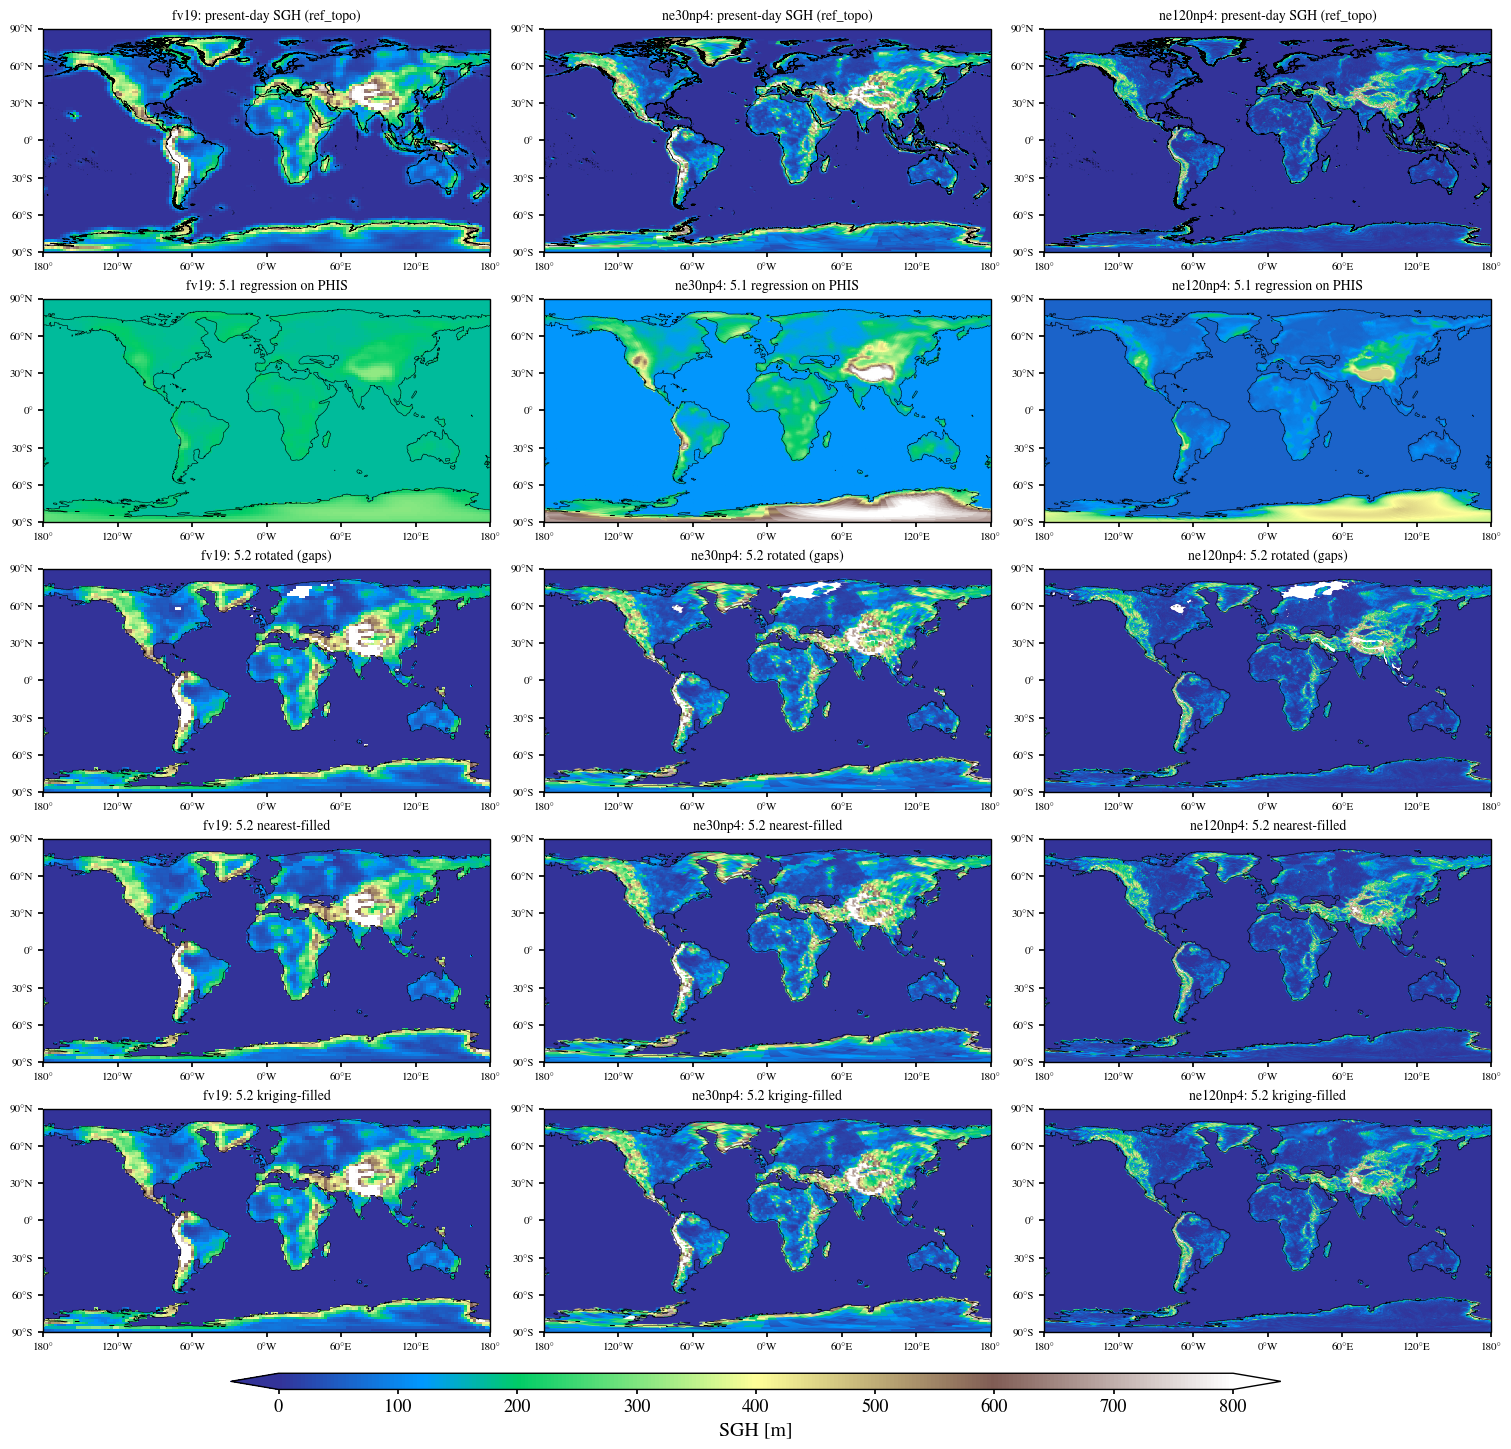

In [17]:
%%time
glon_range, glat_range = [-180, 180], [-90, 90]

rows = [
    ('present-day SGH (ref_topo)', {tgt: xr.open_dataset(cfg['ref_topo']) for tgt, cfg in targets.items()}),
    ('5.1 regression on PHIS', {tgt: xr.open_dataset(cfg['topo_out']) for tgt, cfg in targets.items()}),
    ('5.2 rotated (gaps)', {tgt: xr.open_dataset(cfg['sgh_rot_se_raw']) for tgt, cfg in targets.items()}),
    ('5.2 nearest-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_nn']) for tgt, cfg in targets.items()}),
    ('5.2 kriging-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_krig']) for tgt, cfg in targets.items()}),
]

# Miocene land mask per target, for the ocean -> 0 rule on the 5.2 rows.
mio_land_of = {tgt: xr.open_dataset(cfg['topo_out'])['LANDFRAC'].values > 0 for tgt, cfg in targets.items()}

sgh_kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=800,
    lon_range=glon_range, lat_range=glat_range,
    lonlat_line=True, lon_interval=60, lat_interval=30,
    colorbar=False, nticks=9, label_size=8, title_size=10,
    coast=False, country=False, state=False,
)

fig, axes = plt.subplots(
    5, len(targets), figsize=(5 * len(targets), 13.5), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# ne120np4 is ~777k polygons per panel, so this takes a few minutes.
for r, (label, se_by_tgt) in enumerate(rows):
    kw = dict(sgh_kws, coast=(r == 0))   # modern coastline only on the present-day row
    for c, (tgt, ds_se) in enumerate(se_by_tgt.items()):
        var = 'SGH' if 'SGH' in ds_se else 'SGH_rot'
        vals = ds_se[var].values
        if var == 'SGH_rot':             # 5.2 intermediate -> apply the shipped ocean rule
            vals = np.where(mio_land_of[tgt], vals, 0.0)
        if vals.ndim == 2:   # FV target: explicit axes, no scripgrid needed
            p = Plot_2D(vals, lons=ds_se['lon'].values, lats=ds_se['lat'].values,
                        ax=axes[r, c], title=f'{tgt}: {label}', **kw)
        else:                # SE target: element corners from the scripgrid
            p = Plot_2D(vals, ax=axes[r, c], scrip_file=targets[tgt]['atm_scrip'],
                        title=f'{tgt}: {label}', **kw)

# The 15 Ma shoreline on the palaeo rows. It now does real work: with the ocean
# filled, this is what separates 0 m ocean from genuinely smooth land.
_lon = ((ds_raw025['lon'].values + 180) % 360) - 180
_o = np.argsort(_lon)
for ax in axes[1:].ravel():
    ax.contour(_lon[_o], ds_raw025['lat'].values, ds_raw025['landmask'].values[:, _o], levels=[0.5], colors='k', linewidths=0.4, transform=ccrs.PlateCarree())

cbar_ax = fig.add_axes([0.15, -0.025, 0.70, 0.012])
fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='SGH [m]',
)

for tgt, cfg in targets.items():
    land = mio_land_of[tgt]
    nn = xr.open_dataset(cfg['sgh_rot_se_nn'])['SGH_rot'].values
    kg = xr.open_dataset(cfg['sgh_rot_se_krig'])['SGH_rot'].values
    d = np.abs(nn - kg)[np.isfinite(nn) & np.isfinite(kg)]
    neg = land & np.isfinite(kg) & (kg < 0)
    print(f'{tgt}: |nearest - kriging| over land  mean {d.mean():.1f} m,  max {d.max():.1f} m')
    print(f'   kriging returns SGH < 0 on {int(neg.sum())} land columns '
          f'(min {kg[neg].min():.1f} m)' if neg.any() else
          f'   kriging returns no negative SGH')

fv19: |nearest - kriging| over land  mean 0.7 m,  max 336.2 m
   kriging returns no negative SGH
ne30np4: |nearest - kriging| over land  mean 3.4 m,  max 539.9 m
   kriging returns SGH < 0 on 8 land columns (min -6.7 m)
ne120np4: |nearest - kriging| over land  mean 3.2 m,  max 573.0 m
   kriging returns SGH < 0 on 876 land columns (min -63.0 m)
CPU times: user 34.4 s, sys: 853 ms, total: 35.3 s
Wall time: 35.3 s


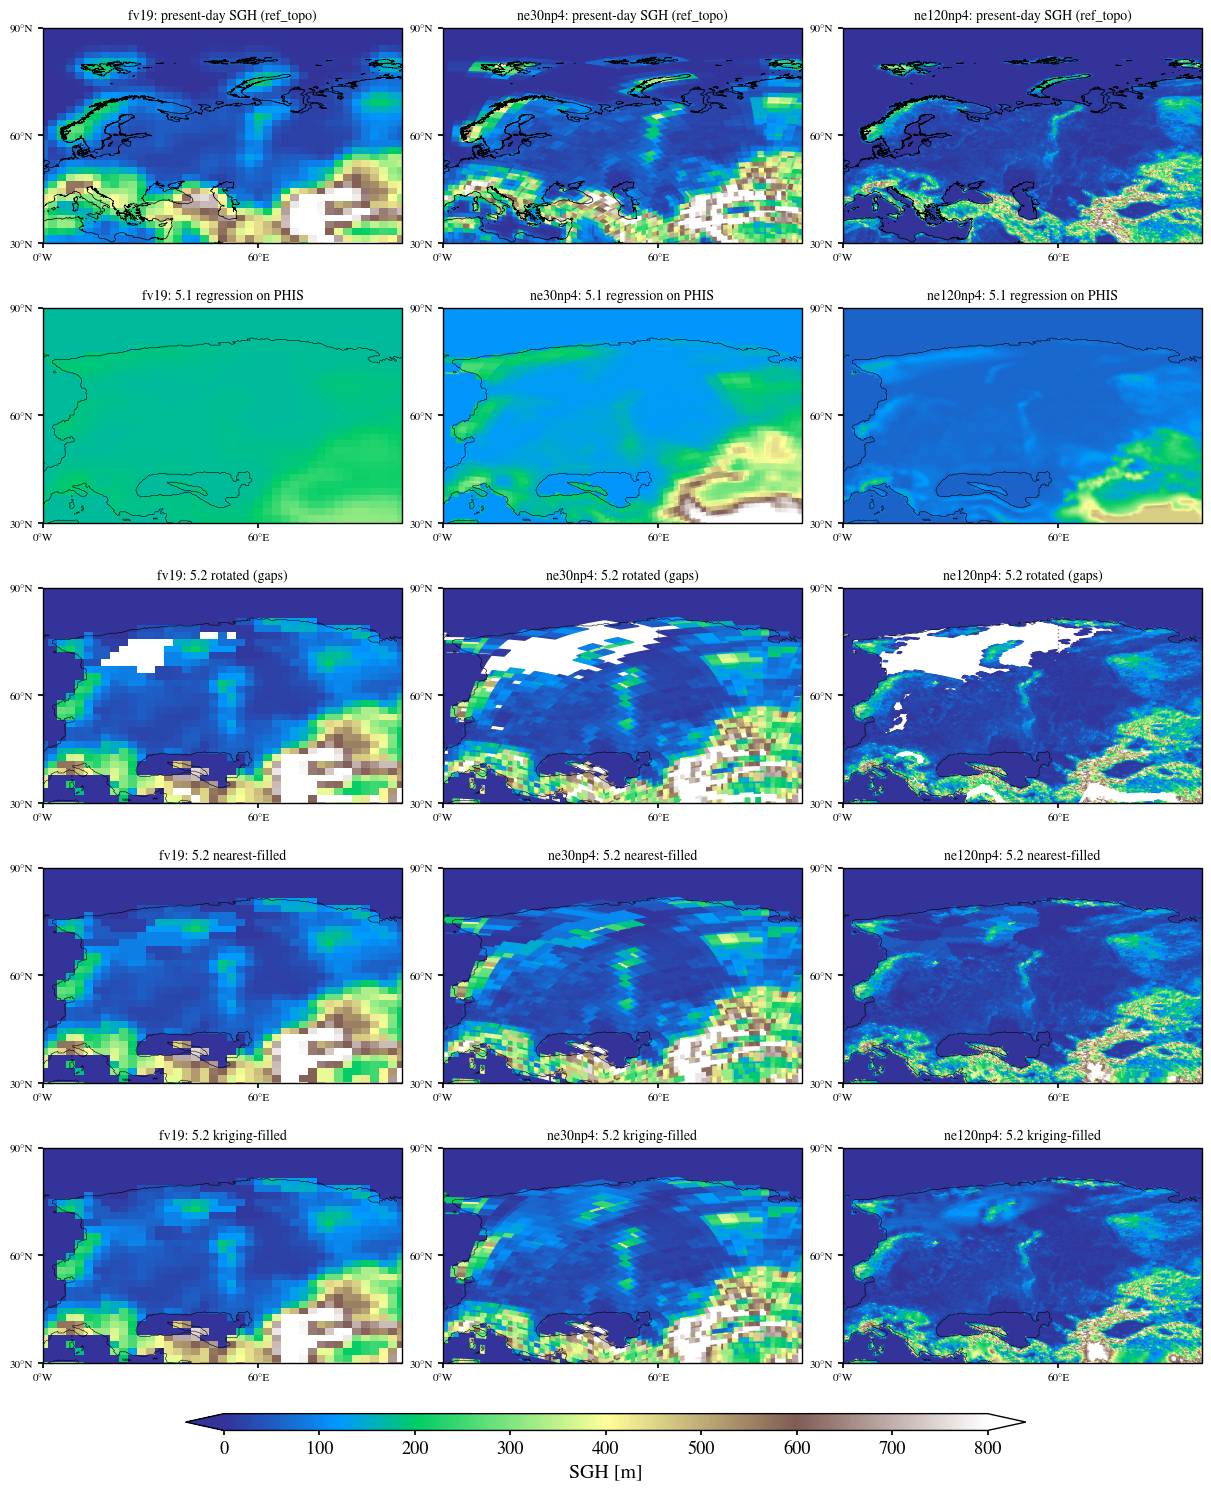

In [18]:
%%time

glon_range, glat_range = [0, 100], [30, 90]

rows = [
    ('present-day SGH (ref_topo)', {tgt: xr.open_dataset(cfg['ref_topo']) for tgt, cfg in targets.items()}),
    ('5.1 regression on PHIS', {tgt: xr.open_dataset(cfg['topo_out']) for tgt, cfg in targets.items()}),
    ('5.2 rotated (gaps)', {tgt: xr.open_dataset(cfg['sgh_rot_se_raw']) for tgt, cfg in targets.items()}),
    ('5.2 nearest-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_nn']) for tgt, cfg in targets.items()}),
    ('5.2 kriging-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_krig']) for tgt, cfg in targets.items()}),
]

# Miocene land mask per target, for the ocean -> 0 rule on the 5.2 rows.
mio_land_of = {tgt: xr.open_dataset(cfg['topo_out'])['LANDFRAC'].values > 0
               for tgt, cfg in targets.items()}

sgh_kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=800,
    lon_range=glon_range, lat_range=glat_range,
    lonlat_line=True, lon_interval=60, lat_interval=30,
    colorbar=False, nticks=9, label_size=8, title_size=10,
    coast=False, country=False, state=False,
)

fig, axes = plt.subplots(
    5, len(targets), figsize=(4 * len(targets), 14), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# ne120np4 is ~777k polygons per panel, so this takes a few minutes.
for r, (label, se_by_tgt) in enumerate(rows):
    kw = dict(sgh_kws, coast=(r == 0))   # modern coastline only on the present-day row
    for c, (tgt, ds_se) in enumerate(se_by_tgt.items()):
        var = 'SGH' if 'SGH' in ds_se else 'SGH_rot'
        vals = ds_se[var].values
        if var == 'SGH_rot':             # 5.2 intermediate -> apply the shipped ocean rule
            vals = np.where(mio_land_of[tgt], vals, 0.0)
        if vals.ndim == 2:   # FV target: explicit axes, no scripgrid needed
            p = Plot_2D(vals, lons=ds_se['lon'].values, lats=ds_se['lat'].values,
                        ax=axes[r, c], title=f'{tgt}: {label}', **kw)
        else:                # SE target: element corners from the scripgrid
            p = Plot_2D(vals, ax=axes[r, c], scrip_file=targets[tgt]['atm_scrip'],
                        title=f'{tgt}: {label}', **kw)

# The 15 Ma shoreline on the palaeo rows. It now does real work: with the ocean
# filled, this is what separates 0 m ocean from genuinely smooth land.
_lon = ((ds_raw025['lon'].values + 180) % 360) - 180
_o = np.argsort(_lon)
for ax in axes[1:].ravel():
    ax.contour(_lon[_o], ds_raw025['lat'].values, ds_raw025['landmask'].values[:, _o],
               levels=[0.5], colors='k', linewidths=0.4, transform=ccrs.PlateCarree())

cbar_ax = fig.add_axes([0.15, -0.025, 0.70, 0.012])
fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='SGH [m]',
)

for tgt, cfg in targets.items():
    land = mio_land_of[tgt]
    nn = xr.open_dataset(cfg['sgh_rot_se_nn'])['SGH_rot'].values
    kg = xr.open_dataset(cfg['sgh_rot_se_krig'])['SGH_rot'].values
    d = np.abs(nn - kg)[np.isfinite(nn) & np.isfinite(kg)]
    neg = land & np.isfinite(kg) & (kg < 0)
    print(f'{tgt}: |nearest - kriging| over land  mean {d.mean():.1f} m,  max {d.max():.1f} m')
    print(f'   kriging returns SGH < 0 on {int(neg.sum())} land columns '
          f'(min {kg[neg].min():.1f} m)' if neg.any() else
          f'   kriging returns no negative SGH')

### SGH30

The same five-way comparison for `SGH30`, the finer-band roughness
(30 s to 10 min in the present-day reference files). Amplitudes are roughly
half of `SGH`, hence the tighter color range.

fv19: |nearest - kriging| over land  mean 0.2 m,  max 124.0 m
   kriging returns no negative SGH30
ne30np4: |nearest - kriging| over land  mean 0.8 m,  max 154.7 m
   kriging returns SGH30 < 0 on 23 land columns (min -2.8 m)
ne120np4: |nearest - kriging| over land  mean 1.2 m,  max 222.8 m
   kriging returns SGH30 < 0 on 2123 land columns (min -68.5 m)
CPU times: user 34.8 s, sys: 729 ms, total: 35.5 s
Wall time: 35.5 s


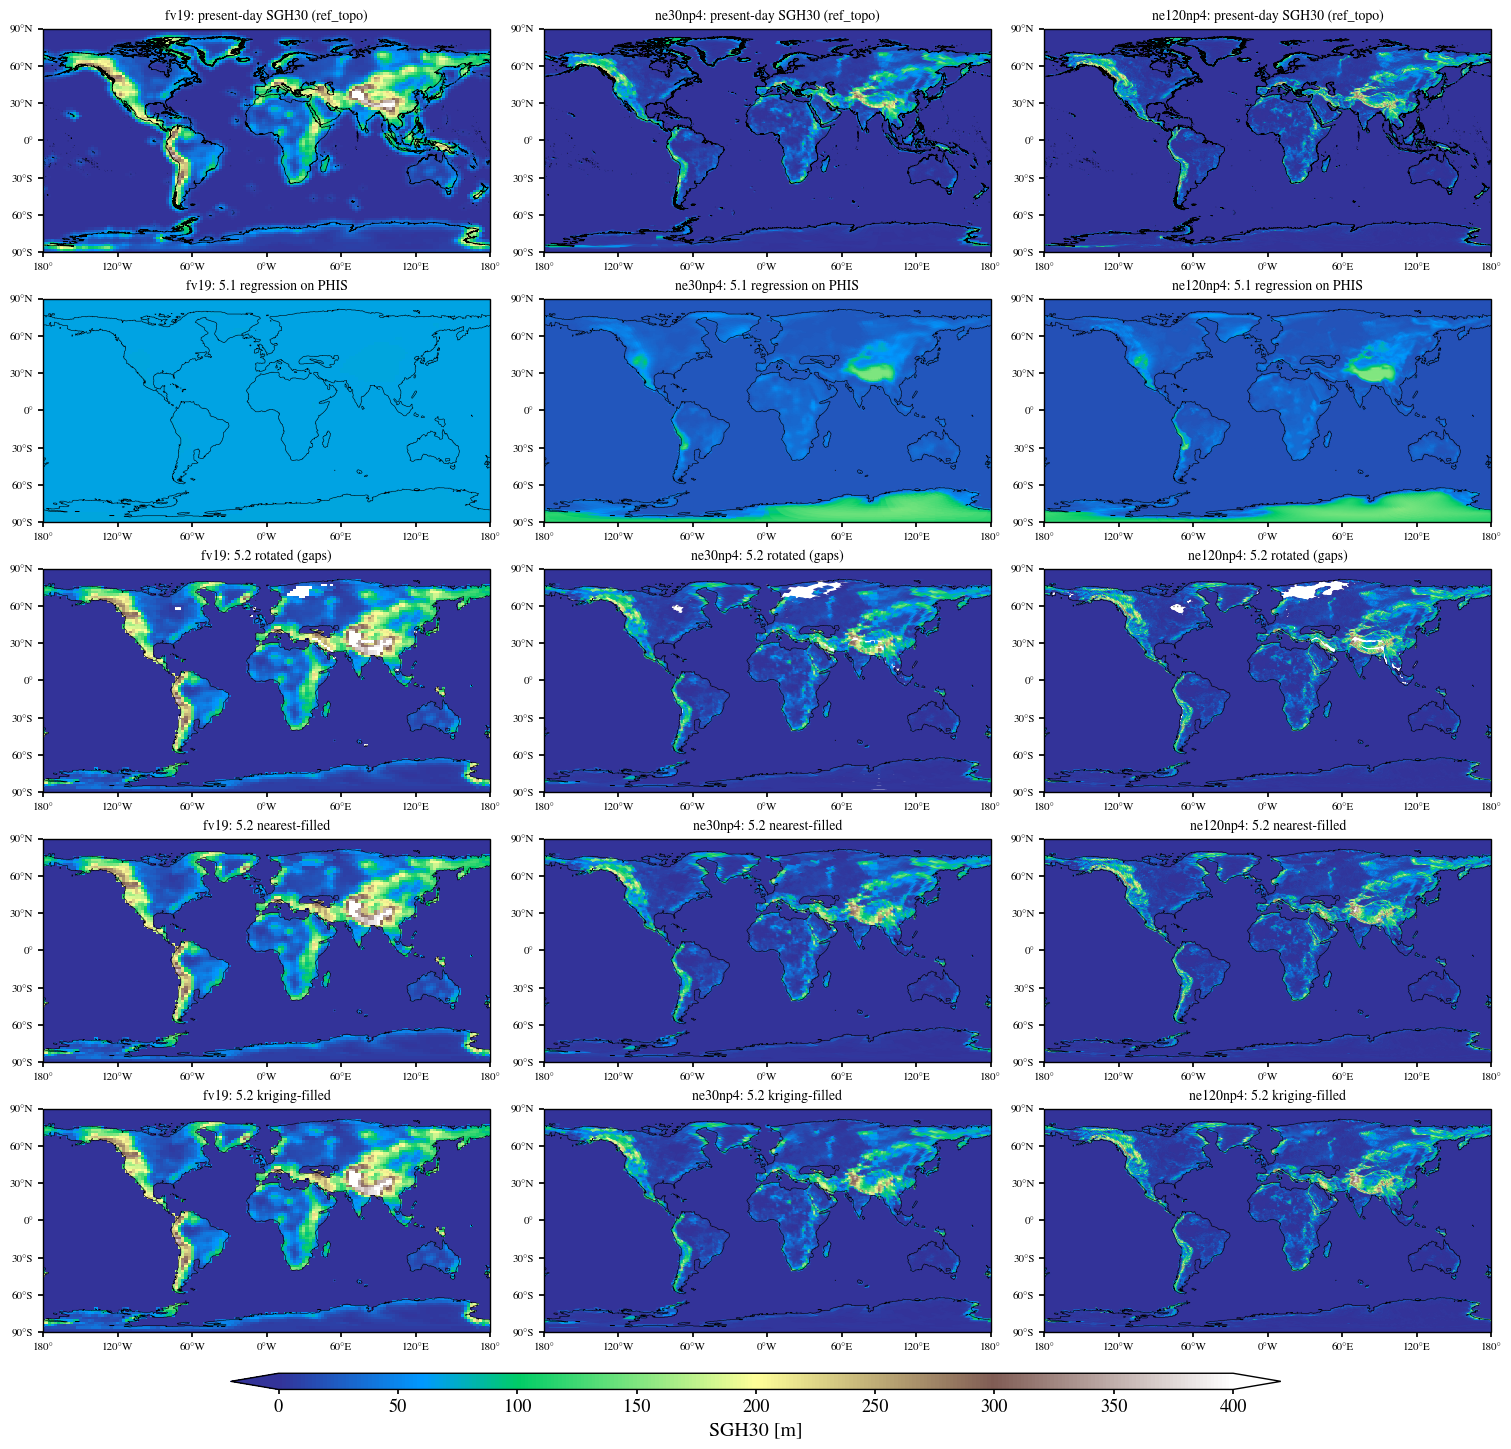

In [19]:
%%time
glon_range, glat_range = [-180, 180], [-90, 90]

rows = [
    ('present-day SGH30 (ref_topo)', {tgt: xr.open_dataset(cfg['ref_topo']) for tgt, cfg in targets.items()}),
    ('5.1 regression on PHIS', {tgt: xr.open_dataset(cfg['topo_out']) for tgt, cfg in targets.items()}),
    ('5.2 rotated (gaps)', {tgt: xr.open_dataset(cfg['sgh_rot_se_raw']) for tgt, cfg in targets.items()}),
    ('5.2 nearest-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_nn']) for tgt, cfg in targets.items()}),
    ('5.2 kriging-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_krig']) for tgt, cfg in targets.items()}),
]

# Miocene land mask per target, for the ocean -> 0 rule on the 5.2 rows.
mio_land_of = {tgt: xr.open_dataset(cfg['topo_out'])['LANDFRAC'].values > 0 for tgt, cfg in targets.items()}

sgh_kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=400,
    lon_range=glon_range, lat_range=glat_range,
    lonlat_line=True, lon_interval=60, lat_interval=30,
    colorbar=False, nticks=9, label_size=8, title_size=10,
    coast=False, country=False, state=False,
)

fig, axes = plt.subplots(
    5, len(targets), figsize=(5 * len(targets), 13.5), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# ne120np4 is ~777k polygons per panel, so this takes a few minutes.
for r, (label, se_by_tgt) in enumerate(rows):
    kw = dict(sgh_kws, coast=(r == 0))   # modern coastline only on the present-day row
    for c, (tgt, ds_se) in enumerate(se_by_tgt.items()):
        var = 'SGH30' if 'SGH30' in ds_se else 'SGH30_rot'
        vals = ds_se[var].values
        if var == 'SGH30_rot':             # 5.2 intermediate -> apply the shipped ocean rule
            vals = np.where(mio_land_of[tgt], vals, 0.0)
        if vals.ndim == 2:   # FV target: explicit axes, no scripgrid needed
            p = Plot_2D(vals, lons=ds_se['lon'].values, lats=ds_se['lat'].values,
                        ax=axes[r, c], title=f'{tgt}: {label}', **kw)
        else:                # SE target: element corners from the scripgrid
            p = Plot_2D(vals, ax=axes[r, c], scrip_file=targets[tgt]['atm_scrip'],
                        title=f'{tgt}: {label}', **kw)

# The 15 Ma shoreline on the palaeo rows. It now does real work: with the ocean
# filled, this is what separates 0 m ocean from genuinely smooth land.
_lon = ((ds_raw025['lon'].values + 180) % 360) - 180
_o = np.argsort(_lon)
for ax in axes[1:].ravel():
    ax.contour(_lon[_o], ds_raw025['lat'].values, ds_raw025['landmask'].values[:, _o], levels=[0.5], colors='k', linewidths=0.4, transform=ccrs.PlateCarree())

cbar_ax = fig.add_axes([0.15, -0.025, 0.70, 0.012])
fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='SGH30 [m]',
)

for tgt, cfg in targets.items():
    land = mio_land_of[tgt]
    nn = xr.open_dataset(cfg['sgh_rot_se_nn'])['SGH30_rot'].values
    kg = xr.open_dataset(cfg['sgh_rot_se_krig'])['SGH30_rot'].values
    d = np.abs(nn - kg)[np.isfinite(nn) & np.isfinite(kg)]
    neg = land & np.isfinite(kg) & (kg < 0)
    print(f'{tgt}: |nearest - kriging| over land  mean {d.mean():.1f} m,  max {d.max():.1f} m')
    print(f'   kriging returns SGH30 < 0 on {int(neg.sum())} land columns '
          f'(min {kg[neg].min():.1f} m)' if neg.any() else
          f'   kriging returns no negative SGH30')

fv19: |nearest - kriging| over land  mean 0.2 m,  max 124.0 m
   kriging returns no negative SGH30
ne30np4: |nearest - kriging| over land  mean 0.8 m,  max 154.7 m
   kriging returns SGH30 < 0 on 23 land columns (min -2.8 m)
ne120np4: |nearest - kriging| over land  mean 1.2 m,  max 222.8 m
   kriging returns SGH30 < 0 on 2123 land columns (min -68.5 m)
CPU times: user 34.6 s, sys: 696 ms, total: 35.3 s
Wall time: 35.3 s


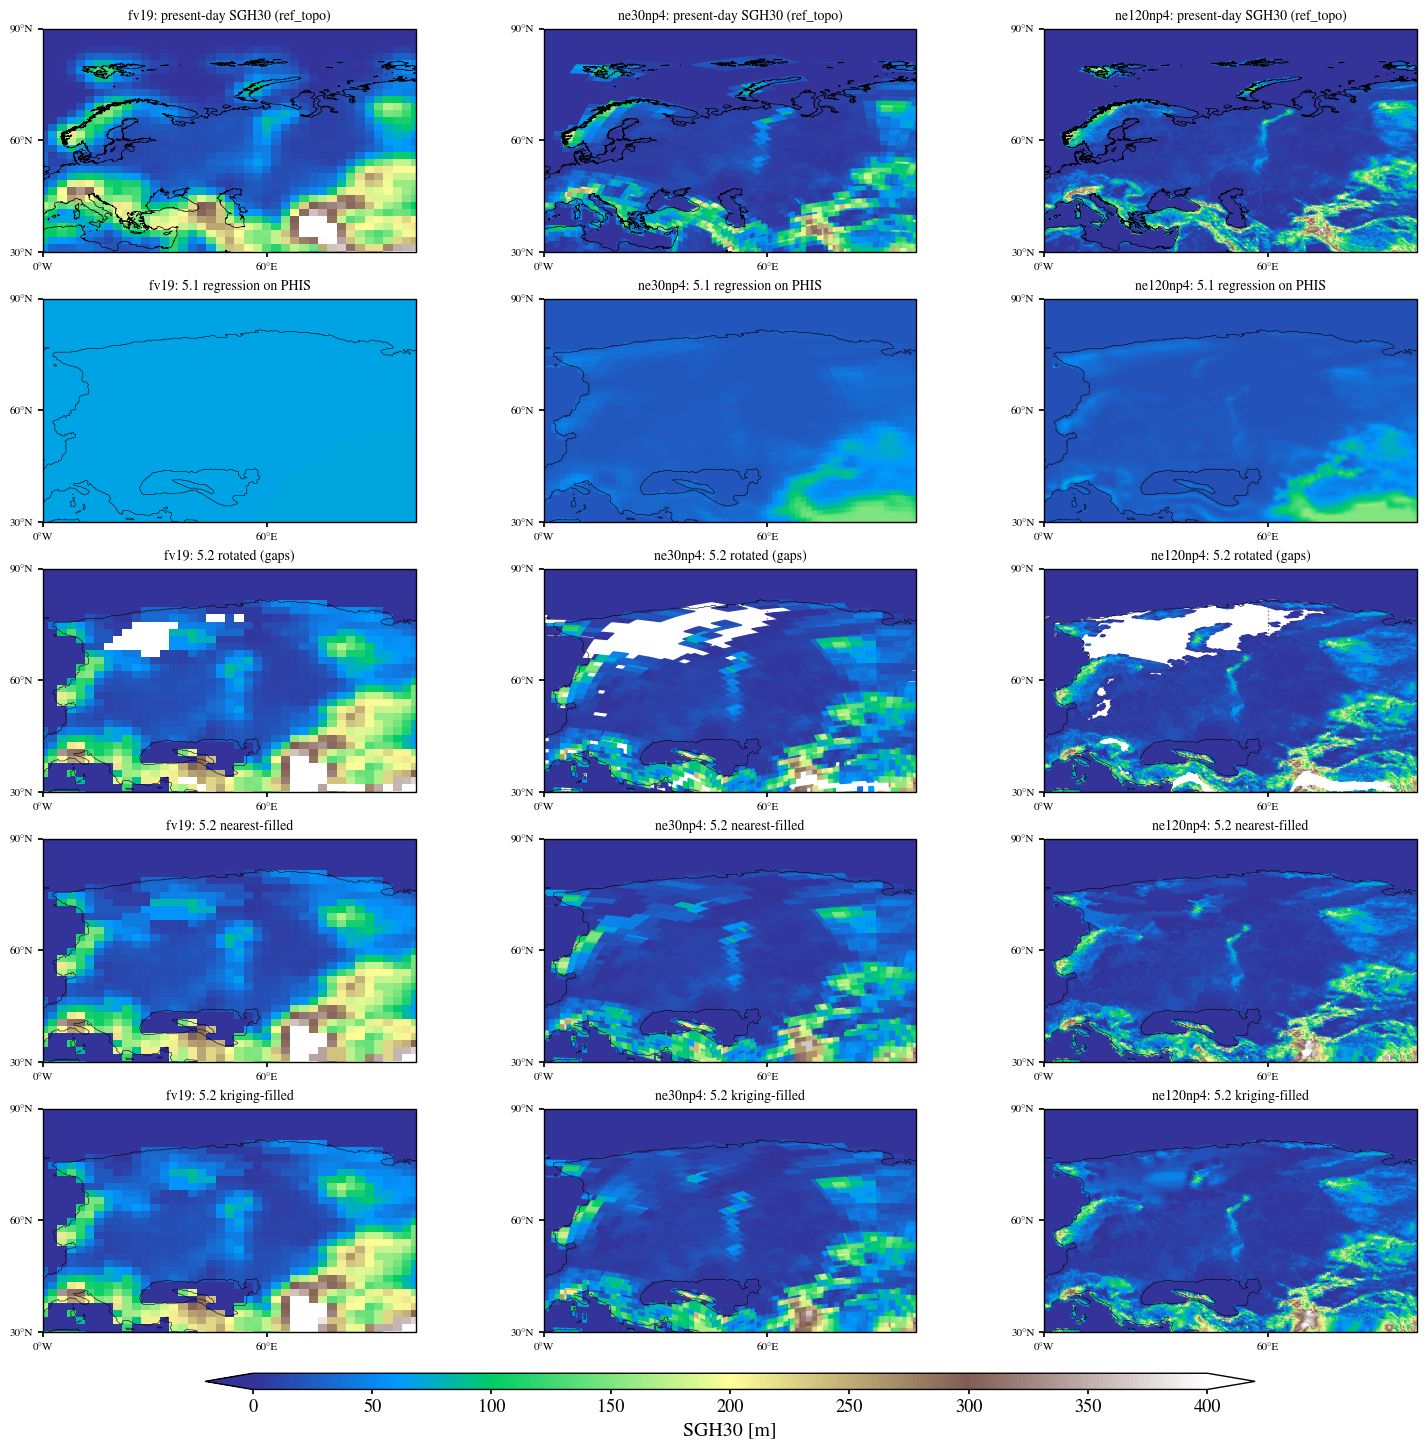

In [20]:
%%time
glon_range, glat_range = [0, 100], [30, 90]

rows = [
    ('present-day SGH30 (ref_topo)', {tgt: xr.open_dataset(cfg['ref_topo']) for tgt, cfg in targets.items()}),
    ('5.1 regression on PHIS', {tgt: xr.open_dataset(cfg['topo_out']) for tgt, cfg in targets.items()}),
    ('5.2 rotated (gaps)', {tgt: xr.open_dataset(cfg['sgh_rot_se_raw']) for tgt, cfg in targets.items()}),
    ('5.2 nearest-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_nn']) for tgt, cfg in targets.items()}),
    ('5.2 kriging-filled', {tgt: xr.open_dataset(cfg['sgh_rot_se_krig']) for tgt, cfg in targets.items()}),
]

# Miocene land mask per target, for the ocean -> 0 rule on the 5.2 rows.
mio_land_of = {tgt: xr.open_dataset(cfg['topo_out'])['LANDFRAC'].values > 0 for tgt, cfg in targets.items()}

sgh_kws = dict(
    cmap=plt.cm.terrain, cmin=0, cmax=400,
    lon_range=glon_range, lat_range=glat_range,
    lonlat_line=True, lon_interval=60, lat_interval=30,
    colorbar=False, nticks=9, label_size=8, title_size=10,
    coast=False, country=False, state=False,
)

fig, axes = plt.subplots(
    5, len(targets), figsize=(5 * len(targets), 13.5), constrained_layout=True,
    subplot_kw={'projection': ccrs.PlateCarree()},
)

# ne120np4 is ~777k polygons per panel, so this takes a few minutes.
for r, (label, se_by_tgt) in enumerate(rows):
    kw = dict(sgh_kws, coast=(r == 0))   # modern coastline only on the present-day row
    for c, (tgt, ds_se) in enumerate(se_by_tgt.items()):
        var = 'SGH30' if 'SGH30' in ds_se else 'SGH30_rot'
        vals = ds_se[var].values
        if var == 'SGH30_rot':             # 5.2 intermediate -> apply the shipped ocean rule
            vals = np.where(mio_land_of[tgt], vals, 0.0)
        if vals.ndim == 2:   # FV target: explicit axes, no scripgrid needed
            p = Plot_2D(vals, lons=ds_se['lon'].values, lats=ds_se['lat'].values,
                        ax=axes[r, c], title=f'{tgt}: {label}', **kw)
        else:                # SE target: element corners from the scripgrid
            p = Plot_2D(vals, ax=axes[r, c], scrip_file=targets[tgt]['atm_scrip'],
                        title=f'{tgt}: {label}', **kw)

# The 15 Ma shoreline on the palaeo rows. It now does real work: with the ocean
# filled, this is what separates 0 m ocean from genuinely smooth land.
_lon = ((ds_raw025['lon'].values + 180) % 360) - 180
_o = np.argsort(_lon)
for ax in axes[1:].ravel():
    ax.contour(_lon[_o], ds_raw025['lat'].values, ds_raw025['landmask'].values[:, _o], levels=[0.5], colors='k', linewidths=0.4, transform=ccrs.PlateCarree())

cbar_ax = fig.add_axes([0.15, -0.025, 0.70, 0.012])
fig.colorbar(
    p.im, cax=cbar_ax, extend='both', orientation='horizontal',
    ticks=p.colorticks, label='SGH30 [m]',
)

for tgt, cfg in targets.items():
    land = mio_land_of[tgt]
    nn = xr.open_dataset(cfg['sgh_rot_se_nn'])['SGH30_rot'].values
    kg = xr.open_dataset(cfg['sgh_rot_se_krig'])['SGH30_rot'].values
    d = np.abs(nn - kg)[np.isfinite(nn) & np.isfinite(kg)]
    neg = land & np.isfinite(kg) & (kg < 0)
    print(f'{tgt}: |nearest - kriging| over land  mean {d.mean():.1f} m,  max {d.max():.1f} m')
    print(f'   kriging returns SGH30 < 0 on {int(neg.sum())} land columns '
          f'(min {kg[neg].min():.1f} m)' if neg.any() else
          f'   kriging returns no negative SGH30')